# Chapter 40: General-Purpose Technologies, Diffusion, Learning, and Complementary Assets

This notebook reruns four worked examples from the chapter: the Bass diffusion curve, bottleneck relief in a repair center, Amdahl's law with communication cost and staged research as an option. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def bass_discrete(m, p, q, N0=0.0, T=10):
    """bass-diffusion-model, annual discrete approximation: flow_t = (p + q N/m)(m - N).
    Returns (flows, cumulative) for years 1..T. Book (ch040): m 1,000, p 0.02,
    q 0.30 gives 20, 25.48, about 32.1; q 0 gives 20, 19.6, about 19.2."""
    flows, cum, N = [], [], float(N0)
    for _ in range(T):
        f = (p + q * N / m) * (m - N)
        N += f
        flows.append(f)
        cum.append(N)
    return flows, cum


def bass_peak(m, p, q):
    """bass-diffusion-model: continuous-time peak at N* = m(q - p)/(2q) when q > p, else None."""
    return m * (q - p) / (2 * q) if q > p else None


def bottleneck_throughput(capacities):
    """bottleneck-relief-general-purpose-methods: X = min of stage capacities and demand.
    Book (ch040): min(18, 10, 15, 20) = 10."""
    return min(capacities)


def amdahl_runtime(W, s, N, comm_per_proc=0.0):
    """parallelization-economies-scale-elasticity: W(s + (1 - s)/N) + comm_per_proc N hours.
    Book (ch040): 100(0.20 + 0.80/10) = 28; P 15.95, 10.725; with 0.4N, 19.95 and 18.725."""
    return W * (s + (1 - s) / N) + comm_per_proc * N


def staged_option_value(pilot_cost, prob, value, followon_cost):
    """public-goods-knowledge-spillovers: NPV = -C0 + p max(V - C1, 0).
    Book (ch040): -100,000 + 0.10 max(3,000,000 - 500,000, 0) = 150,000; private value 600,000 gives -90,000."""
    return -float(pilot_cost) + prob * max(float(value) - float(followon_cost), 0.0)


def committed_value(pilot_cost, prob, value, followon_cost):
    """public-goods-knowledge-spillovers: both costs paid before any signal, p V - (C0 + C1).
    Book (ch040): 0.10(3,000,000) - 600,000 = -300,000."""
    return prob * float(value) - (float(pilot_cost) + float(followon_cost))


def prob_at_least_one(p, n):
    """1 - (1 - p)^n."""
    return 1.0 - (1.0 - p) ** n


plt.rcParams.update(HOUSE_RC)


growth = SimpleNamespace(bass_discrete=bass_discrete)


industrial = SimpleNamespace(bass_peak=bass_peak, bottleneck_throughput=bottleneck_throughput, committed_value=committed_value)


production = SimpleNamespace(amdahl_runtime=amdahl_runtime)


finance = SimpleNamespace(staged_option_value=staged_option_value)


choice = SimpleNamespace(prob_at_least_one=prob_at_least_one)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'bass-diffusion-model': {'m': 1000,
                          'p': 0.02,
                          'q': 0.3,
                          'N0': 0,
                          'flows': (20, 25.48, 32.1),
                          'N2': 45.48,
                          'flows_q0': (20, 19.6, 19.2),
                          'seed': 10,
                          'seed_flow': 2.97},
 'bottleneck-relief-general-purpose-methods': {'intake': 18,
                                               'diagnosis': 10,
                                               'repair': 15,
                                               'demand': 20,
                                               'contribution': 120,
                                               'throughput': 10,
                                               'base': 1200,
                                               'tool_capacity': 14,
                                               'tool_cost': 300,
                                               'tool_gain': 180,
                                               'upgrade_capacity': 17,
                                               'upgrade_cost': 150,
                                               'low_demand': 12,
                                               'low_demand_added': 240},
 'parallelization-economies-scale-elasticity': {'W_R': 100,
                                                's_R': 0.2,
                                                'W_P': 110,
                                                's_P': 0.05,
                                                'R10': 28,
                                                'R20': 24,
                                                'R_cut': 0.143,
                                                'P10': 15.95,
                                                'P20': 10.725,
                                                'P_cut': 0.328,
                                                'comm': 0.4,
                                                'P10c': 19.95,
                                                'P20c': 18.725,
                                                'rate': 6,
                                                'cost10': 1197,
                                                'cost20': 2247,
                                                'extra': 1050,
                                                'saved': 1.225,
                                                'hour_value': 50,
                                                'saved_value': 61.25},
 'public-goods-knowledge-spillovers': {'pilot': 100000,
                                       'prob': 0.1,
                                       'development': 500000,
                                       'social': 3000000,
                                       'private': 600000,
                                       'social_staged': 150000,
                                       'private_staged': -90000,
                                       'pilots': 10,
                                       'at_least_one': 0.651,
                                       'committed_social': -300000},
 'constructed': {'bass-diffusion-model': {'p': [0.01, 0.04], 'q': [0.5]},
                 'bottleneck-relief-general-purpose-methods': {'note': 'diagnosis 17 with demand '
                                                                       '12 combined'},
                 'parallelization-economies-scale-elasticity': {'R_with_comm': True},
                 'public-goods-knowledge-spillovers': {'prob': [0.05, 0.2]}}}


def trim(x, digits=2):
    """Number with trailing zeros removed: 0.30 -> 0.3, 20.00 -> 20."""
    text = num(x, digits)
    return text.rstrip("0").rstrip(".") if "." in text else text


def bass_picture(p=0.02, q=0.30):
    m = BV["bass-diffusion-model"]["m"]
    flows, cum = growth.bass_discrete(m, p, q, 0, 10)
    peak = industrial.bass_peak(m, p, q)
    years = np.arange(1, 11)
    fig, (ax, ax2) = new_figure(ncols=2)
    ax.bar(years, flows, color=PALETTE["teal"], width=0.6)
    ax.set_ylabel("New adopters in the year")
    ax.set_xlabel("Year")
    ax.set_xticks(years)
    ax.set_ylim(0, 150)
    ax2.plot(years, cum, color=PALETTE["navy"], linewidth=2.2, marker="o", markersize=4)
    if peak is not None:
        hline(ax2, peak, f"continuous peak N* = {num(peak, 1)}", col="gold", x_frac=0.02)
    ax2.set_xticks(years)
    ax2.set_ylim(0, 1_000)
    ax2.set_xlabel("Year")
    ax2.set_ylabel("Cumulative adopters N")
    accel = flows[1] > flows[0]
    n1 = cum[0]
    metrics = {"Year 1 flow": num(flows[0]), "Year 2 flow": num(flows[1]), "Year 3 flow": num(flows[2]),
               "Cumulative N after 10 years": num(cum[-1], 1),
               "Continuous peak N*": num(peak, 1) if peak is not None else "no interior peak (q not above p)"}
    share1 = n1 / m
    interp = (f"Year 1: ({trim(p)} + {trim(q)} x 0)(1,000) = {num(flows[0])}, so N_1 = {num(n1)}. Year 2: "
              f"({trim(p)} + {trim(q)} x {num(share1, 2)})({num(m - n1)}) = {num(flows[1])}. Sales "
              f"{'accelerate because the installed-share term grows faster than the market depletes' if accel else 'fall from the start because the imitation term cannot outrun depletion'}. "
              + (f"In continuous time sales peak at N* = 1,000 x ({trim(q)} - {trim(p)}) / (2 x {trim(q)}) = {num(peak, 1)}."
                 if peak is not None else "With q not above p there is no interior sales peak."))
    steps = [f"Flow 1 = ({trim(p)} + {trim(q)} x 0) x 1,000 = {num(flows[0])}",
             f"N_1 = {num(n1)}, share {num(share1, 2)}",
             f"Flow 2 = ({trim(p)} + {trim(q)} x {num(share1, 2)}) x {num(m - n1)} = {num(flows[1])}",
             f"Flow 3 = ({trim(p)} + {trim(q)} x {num(cum[1] / m, 5)}) x {num(m - cum[1])} = {num(flows[2])}"]
    alt = (f"Annual new adopters and cumulative adopters over ten years with p = {trim(p)} and q = {trim(q)}: flows "
           f"start at {num(flows[0])} and cumulative adoption reaches {num(cum[-1], 1)} of 1,000.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def bottleneck_picture(diag=10, demand=20):
    bv = BV["bottleneck-relief-general-purpose-methods"]
    caps = [bv["intake"], diag, bv["repair"], demand]
    x = industrial.bottleneck_throughput(caps)
    equip = {10: 0, 14: 300, 17: 450}[diag]
    gross = x * bv["contribution"]
    net = gross - equip
    base = bv["base"]
    names = ["Intake", "Diagnosis", "Repair", "Demand"]
    binding = [n for n, c in zip(names, caps) if c == x]
    fig, ax = new_figure()
    cols = ["gold" if c == x else "teal" for c in caps]
    bar_compare(ax, names, caps, colors=cols, value_labels=[str(c) for c in caps], ylabel="Devices per day",
                xlabel="Stage")
    hline(ax, x, f"throughput {x}", col="terracotta", x_frac=0.02)
    ax.set_ylim(0, 25)
    change = net - base
    metrics = {"Throughput": str(x), "Binding": " and ".join(binding), "Contribution": money(gross, 0),
               "Equipment cost": money(equip, 0), "Net contribution": money(net, 0),
               "Change from the $1,200 base": ("+" if change > 0 else "") + money(change, 0)}
    interp = (f"Throughput is min(18, {diag}, 15, {demand}) = {x}, so contribution is {x} x 120 = {num(gross, 0)}. "
              f"After {num(equip, 0)} of equipment the net is {num(gross, 0)} - {num(equip, 0)} = {num(net, 0)}, "
              f"{'above' if change > 0 else 'below' if change < 0 else 'equal to'} the 1,200 base by "
              f"{num(abs(change), 0)}. The binding limit is {' and '.join(binding).lower()}.")
    steps = [f"X = min(18, {diag}, 15, {demand}) = {x}", f"Contribution = {x} x 120 = {num(gross, 0)}",
             f"Net = {num(gross, 0)} - {num(equip, 0)} = {num(net, 0)}",
             f"Change = {num(net, 0)} - 1,200 = {num(change, 0)}"]
    alt = (f"Bars for intake 18, diagnosis {diag}, repair 15 and demand {demand}, with the binding limit "
           f"highlighted and throughput {x}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


ARCH = {"R": (100, 0.20), "P": (110, 0.05)}


def amdahl_picture(arch="P", n=10, comm="0.4N"):
    bv = BV["parallelization-economies-scale-elasticity"]
    w, s = ARCH[arch]
    k = 0.4 if comm == "0.4N" else 0.0
    t10, t20 = production.amdahl_runtime(w, s, 10, k), production.amdahl_runtime(w, s, 20, k)
    t = t10 if n == 10 else t20
    rate, hv = bv["rate"], bv["hour_value"]
    c10, c20 = 10 * t10 * rate, 20 * t20 * rate
    cost = c10 if n == 10 else c20
    saved = t10 - t20
    cut = saved / t10
    ns = np.arange(1, 41)
    fig, ax = new_figure()
    ax.plot(ns, [production.amdahl_runtime(w, s, j, k) for j in ns], color=PALETTE["teal"], linewidth=2.2,
            label=f"architecture {arch}" + (", with 0.4N communication" if k else ", no communication"))
    mark(ax, 10, t10, f"10: {num(t10, 3)} h", col="navy" if n == 10 else "grey", dx=8, dy=8)
    mark(ax, 20, t20, f"20: {num(t20, 3)} h", col="navy" if n == 20 else "grey", dx=8, dy=8)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlim(0, 41)
    ax.set_ylim(0, 60)
    ax.set_xlabel("Processors N")
    ax.set_ylabel("Runtime (hours)")
    worth = hv * saved
    extra = c20 - c10
    comm_txt = f" + 0.4 x {n}" if k else ""
    metrics = {f"Runtime at N = {n}": f"{num(t, 3)} h", f"Cost at N = {n}": money(cost, 0),
               "Cut from 10 to 20 processors": pct(cut) if abs(saved) > 1e-9 else "none (tie)",
               "Extra bill for 20": money(extra, 0), "Value of time saved": money(worth)}
    interp = (f"T = {w} x ({trim(s)} + {trim(1 - s)} / {n}){comm_txt} = {num(t, 3)} hours, costing {n} x {num(t, 3)} "
              f"x 6 = {money(cost, 0)}. Going from 10 to 20 processors "
              + (f"cuts runtime from {num(t10, 3)} to {num(t20, 3)} hours ({pct(cut)}), saving {num(saved, 3)} hours "
                 f"worth {num(saved, 3)} x 50 = {money(worth)} against an extra bill of {money(extra, 0)}."
                 if abs(saved) > 1e-9 else
                 f"leaves runtime at {num(t10, 3)} hours: the communication cost eats the whole speedup, while the "
                 f"bill rises by {money(extra, 0)}."))
    steps = [f"T({n}) = {w} x ({trim(s)} + {trim(1 - s)} / {n}){comm_txt} = {num(t, 3)}",
             f"Cost = {n} x {num(t, 3)} x 6 = {money(cost, 0)}",
             f"Saved = {num(t10, 3)} - {num(t20, 3)} = {num(saved, 3)} hours, worth {money(worth)}",
             f"Extra bill = {num(c20, 0)} - {num(c10, 0)} = {money(extra, 0)}"]
    alt = (f"Runtime against processors for architecture {arch}: {num(t10, 3)} hours at 10 processors and "
           f"{num(t20, 3)} at 20.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def option_picture(prob=0.10, view="social"):
    bv = BV["public-goods-knowledge-spillovers"]
    c0, c1 = bv["pilot"], bv["development"]
    value = bv["social"] if view == "social" else bv["private"]
    staged = finance.staged_option_value(c0, prob, value, c1)
    committed = industrial.committed_value(c0, prob, value, c1)
    at_least = choice.prob_at_least_one(prob, bv["pilots"])
    fig, ax = new_figure()
    bar_compare(ax, ["Staged", "Committed up front"], [staged / 1_000, committed / 1_000], colors=["teal", "grey"],
                value_labels=[money(staged, 0), money(committed, 0)], ylabel="Expected value per project ($ thousand)",
                xlabel="Funding plan")
    ax.set_ylim(-700, 550)
    metrics = {"Staged value": money(staged, 0), "Committed value": money(committed, 0),
               "Funds the project": "Yes" if staged > 0 else "No",
               "P(at least one success in 10)": pct(at_least)}
    who = "Society" if view == "social" else "A private funder"
    interp = (f"Staged: -100,000 + {trim(prob)} x max({num(value, 0)} - 500,000, 0) = {money(staged, 0)}. Committed: "
              f"{trim(prob)} x {num(value, 0)} - 600,000 = {money(committed, 0)}. {who} "
              f"{'gains' if staged > 0 else 'loses'} from a staged pilot. Across 10 independent pilots, the chance of "
              f"at least one success is 1 - {trim(1 - prob)}^10 = {pct(at_least)}.")
    steps = [f"Staged = -100,000 + {trim(prob)} x {num(max(value - c1, 0), 0)} = {num(staged, 0)}",
             f"Committed = {trim(prob)} x {num(value, 0)} - 600,000 = {num(committed, 0)}",
             f"P(at least one) = 1 - {trim(1 - prob)}^10 = {pct(at_least)}"]
    alt = (f"Two bars for the {view} valuation at success chance {trim(prob)}: staged value {money(staged, 0)} and "
           f"committed value {money(committed, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Bass diffusion model: the shape of adoption

$$\frac{dN(t)}{dt} =\left(p+q\frac{N(t)}{m}\right)[m-N(t)].$$

With $m=1{,}000$, $p=0.02$, $q=0.30$ and $N_0=0$, the annual approximation gives 20 in year one and

$$(0.02+0.30\times0.02)(980)=25.48,$$

in year two. In continuous time sales peak at

$$N^*=\frac{m(q-p)}{2q}.$$

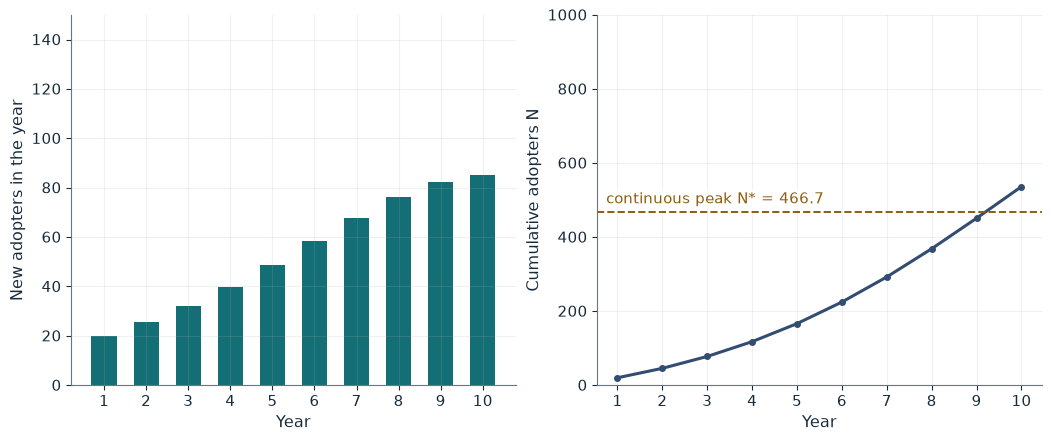

Year 1 flow                  20.00
Year 2 flow                  25.48
Year 3 flow                  32.11
Cumulative N after 10 years  536.2
Continuous peak N*           466.7

Worked steps:
  1. Flow 1 = (0.02 + 0.3 x 0) x 1,000 = 20.00
  2. N_1 = 20.00, share 0.02
  3. Flow 2 = (0.02 + 0.3 x 0.02) x 980.00 = 25.48
  4. Flow 3 = (0.02 + 0.3 x 0.04548) x 954.52 = 32.11

Year 1: (0.02 + 0.3 x 0)(1,000) = 20.00, so N_1 = 20.00. Year 2: (0.02 + 0.3 x 0.02)(980.00) = 25.48. Sales accelerate because the installed-share term grows faster than the market depletes. In continuous time sales peak at N* = 1,000 x (0.3 - 0.02) / (2 x 0.3) = 466.7.


In [2]:
show(bass_picture(p=0.02, q=0.30))

Change one input, `q`, and hold the others at the book's values:

In [3]:
sweep(bass_picture, 'q', [0.0, 0.3, 0.5], {'p': 0.02}, ['Year 1 flow', 'Year 2 flow', 'Year 3 flow'])

q | Year 1 flow | Year 2 flow | Year 3 flow
0.0 | 20.00 | 19.60 | 19.21
0.3 | 20.00 | 25.48 | 32.11
0.5 | 20.00 | 29.40 | 42.49


With $q=0.30$ flows rise from 20 to 25.48 to about 32.1. With $q=0$ they fall, 20, 19.6, 19.21, because only depletion is left.

## 2. Bottleneck relief: upgrade the binding stage

Intake handles 18 devices a day, diagnosis 10, repair 15, and demand is 20:

$$\min(18,10,15,20)=10,$$

worth \$1,200 a day at \$120 per repair. A \$300 tool lifts diagnosis to 14; another \$150 lifts it to 17.

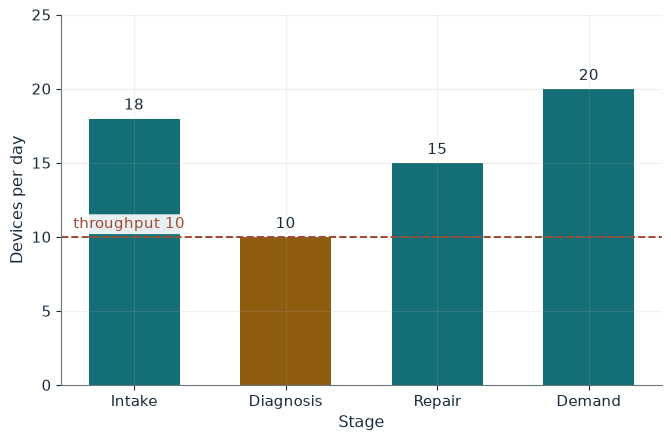

Throughput                   10
Binding                      Diagnosis
Contribution                 $1,200
Equipment cost               $0
Net contribution             $1,200
Change from the $1,200 base  $0

Worked steps:
  1. X = min(18, 10, 15, 20) = 10
  2. Contribution = 10 x 120 = 1,200
  3. Net = 1,200 - 0 = 1,200
  4. Change = 1,200 - 1,200 = 0

Throughput is min(18, 10, 15, 20) = 10, so contribution is 10 x 120 = 1,200. After 0 of equipment the net is 1,200 - 0 = 1,200, equal to the 1,200 base by 0. The binding limit is diagnosis.


In [4]:
show(bottleneck_picture(diag=10, demand=20))

Change one input, `diag`, and hold the others at the book's values:

In [5]:
sweep(bottleneck_picture, 'diag', [10, 14, 17], {'demand': 20}, ['Throughput', 'Binding', 'Net contribution'])

diag | Throughput | Binding | Net contribution
10 | 10 | Diagnosis | $1,200
14 | 14 | Diagnosis | $1,380
17 | 15 | Repair | $1,350


The first tool adds four repairs, \$480, for \$300: a \$180 gain. The second meets the repair limit of 15 and adds one repair worth \$120 for \$150, so it does not pay.

## 3. Parallelization economies: Amdahl's law and communication cost

Architecture R takes 100 one-processor hours with $s=0.20$:

$$100\left(0.20+\frac{0.80}{10}\right)=28\text{ hours},$$

Architecture P takes 110 hours with $s=0.05$. With communication of $0.4N$ hours and \$6 per processor-hour,

$$10(19.95)(\$6)=\$1{,}197$$

$$20(18.725)(\$6)=\$2{,}247.$$

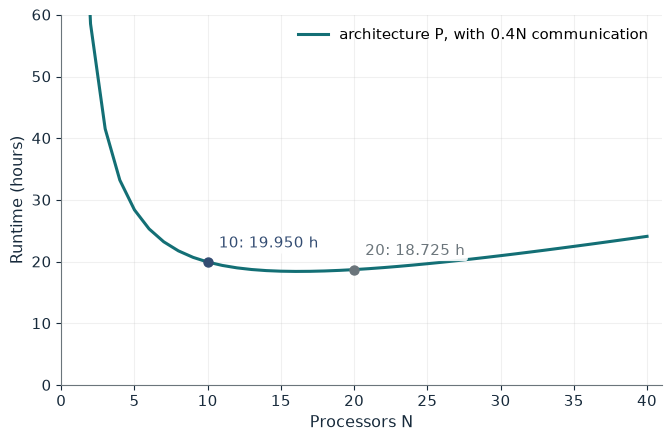

Runtime at N = 10             19.950 h
Cost at N = 10                $1,197
Cut from 10 to 20 processors  6.1%
Extra bill for 20             $1,050
Value of time saved           $61.25

Worked steps:
  1. T(10) = 110 x (0.05 + 0.95 / 10) + 0.4 x 10 = 19.950
  2. Cost = 10 x 19.950 x 6 = $1,197
  3. Saved = 19.950 - 18.725 = 1.225 hours, worth $61.25
  4. Extra bill = 2,247 - 1,197 = $1,050

T = 110 x (0.05 + 0.95 / 10) + 0.4 x 10 = 19.950 hours, costing 10 x 19.950 x 6 = $1,197. Going from 10 to 20 processors cuts runtime from 19.950 to 18.725 hours (6.1%), saving 1.225 hours worth 1.225 x 50 = $61.25 against an extra bill of $1,050.


In [6]:
show(amdahl_picture(arch='P', n=10, comm='0.4N'))

Change one input, `n`, and hold the others at the book's values:

In [7]:
sweep(amdahl_picture, 'n', [10, 20], {'arch': 'P', 'comm': '0.4N'}, ['Extra bill for 20', 'Value of time saved'])

n | Extra bill for 20 | Value of time saved
10 | $1,050 | $61.25
20 | $1,050 | $61.25


Doubling processors saves 1.225 hours worth \$61.25 for an extra bill of \$1,050. Without communication (`comm='none'`) P's runtime falls 32.8 percent; R's falls only 14.3 percent.

## 4. Knowledge spillovers: staged research as an option

A pilot costs \$100,000 and succeeds with probability 0.10; development then costs \$500,000.

$$-\$100{,}000+0.10\max\{\$3{,}000{,}000-\$500{,}000,0\} =\$150{,}000.$$

Across ten pilots,

$$1-(1-0.10)^{10}=1-0.9^{10}\approx65.1\%.$$

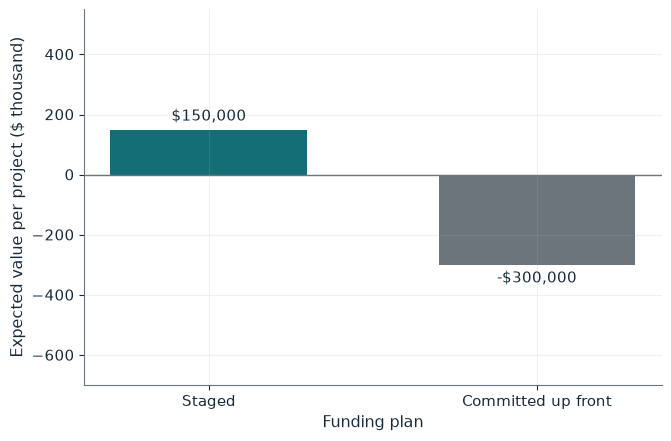

Staged value                   $150,000
Committed value                -$300,000
Funds the project              Yes
P(at least one success in 10)  65.1%

Worked steps:
  1. Staged = -100,000 + 0.1 x 2,500,000 = 150,000
  2. Committed = 0.1 x 3,000,000 - 600,000 = -300,000
  3. P(at least one) = 1 - 0.9^10 = 65.1%

Staged: -100,000 + 0.1 x max(3,000,000 - 500,000, 0) = $150,000. Committed: 0.1 x 3,000,000 - 600,000 = -$300,000. Society gains from a staged pilot. Across 10 independent pilots, the chance of at least one success is 1 - 0.9^10 = 65.1%.


In [8]:
show(option_picture(prob=0.10, view='social'))

Change one input, `prob`, and hold the others at the book's values:

In [9]:
sweep(option_picture, 'prob', [0.05, 0.1, 0.2], {'view': 'social'}, ['Staged value', 'Committed value', 'P(at least one success in 10)'])

prob | Staged value | Committed value | P(at least one success in 10)
0.05 | $25,000 | -$450,000 | 40.1%
0.1 | $150,000 | -$300,000 | 65.1%
0.2 | $400,000 | $0 | 89.3%


Society gains \$150,000 per staged pilot, but a private funder capturing \$600,000 loses \$90,000 (`view='private'`). Committing both costs up front loses \$300,000 even socially: the value comes from the option to stop.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

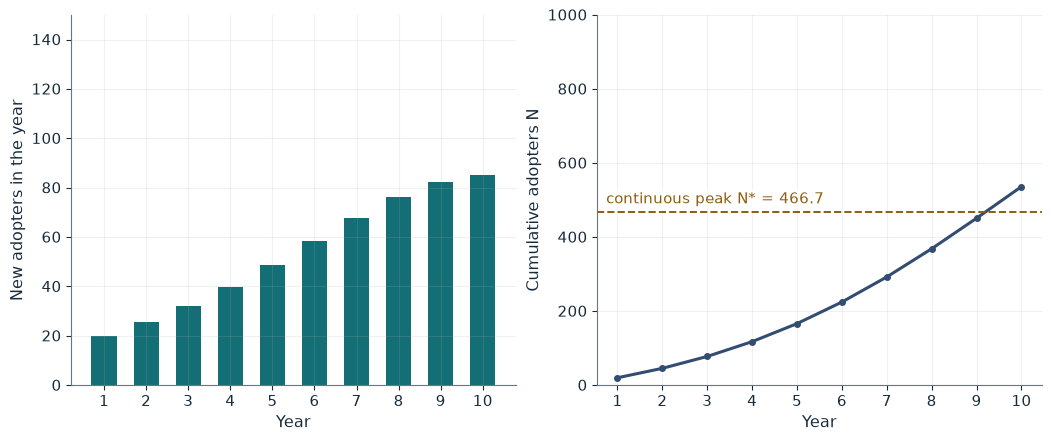

Year 1 flow                  20.00
Year 2 flow                  25.48
Year 3 flow                  32.11
Cumulative N after 10 years  536.2
Continuous peak N*           466.7

Worked steps:
  1. Flow 1 = (0.02 + 0.3 x 0) x 1,000 = 20.00
  2. N_1 = 20.00, share 0.02
  3. Flow 2 = (0.02 + 0.3 x 0.02) x 980.00 = 25.48
  4. Flow 3 = (0.02 + 0.3 x 0.04548) x 954.52 = 32.11

Year 1: (0.02 + 0.3 x 0)(1,000) = 20.00, so N_1 = 20.00. Year 2: (0.02 + 0.3 x 0.02)(980.00) = 25.48. Sales accelerate because the installed-share term grows faster than the market depletes. In continuous time sales peak at N* = 1,000 x (0.3 - 0.02) / (2 x 0.3) = 466.7.


In [10]:
show(bass_picture(p=0.02, q=0.30))

## Practice

**1.** With $p=0.04$ and $q=0.30$, what is the year-two adoption flow?

<details><summary>Answer</summary>

N_1 = 40; (0.04 + 0.30 x 0.04)(960) = 0.052 x 960 = 49.92.

</details>

**2.** With demand 12 and diagnosis 17, what is net contribution?

<details><summary>Answer</summary>

min(18, 17, 15, 12) = 12; 12 x 120 = 1,440, minus 450 = 990, below the 1,200 base.

</details>

**3.** At a success chance of 0.20, what is the social staged value of one pilot?

<details><summary>Answer</summary>

-100,000 + 0.20 x 2,500,000 = \$400,000.

</details>